# Assignment № 3 — Task 1: Sentiment Analysis

**Цель:** сравнить три подхода для классификации англоязычных твитов на `negative`, `neutral`, `positive`:
1. VADER (lexicon-based).
2. TF-IDF + Logistic Regression.
3. Предварительно обученный Transformer `cardiffnlp/twitter-roberta-base-sentiment-latest`.

**Датасет:** загруженный `train.csv`. В нём есть столбцы `text` и `sentiment`, поэтому для классификации используем полный текст твита (`text`), а не `selected_text`. Модель Transformer не дообучается, как требует задание.

Запускай ячейки сверху вниз. Итоговые метрики должны быть получены реальным выполнением ноутбука; заранее фиксировать или придумывать значения нельзя.

## 1. Установка библиотек

Если библиотек не хватает, выполни ячейку установки. После установки иногда нужно перезапустить kernel.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk transformers torch tqdm

Note: you may need to restart the kernel to use updated packages.


## 2. Импорт библиотек и настройка воспроизводимости

`RANDOM_STATE` фиксирует случайное разделение данных. Для повторяемости также сохраняем версии и параметры используемых моделей в ноутбуке.

In [2]:
import os
import re
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk
import torch
import transformers

from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from tqdm.auto import tqdm

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("Random seed:", RANDOM_STATE)

C:\Users\Daniyar\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.13.2
pandas: 2.3.3
scikit-learn: 1.8.0
transformers: 5.20.2
PyTorch: 2.14.1+cpu
Random seed: 42


## 3. Загрузка и проверка данных

Файл `train.csv` должен находиться в той же папке, что и ноутбук. В этой версии используется `encoding="cp1252"`, потому что загруженный CSV содержит символы, из-за которых стандартное чтение UTF-8 может завершиться ошибкой.

Проверяем размер, названия столбцов, пропуски, дубликаты и распределение классов.

In [18]:
DATA_PATH = "data/sentiment_tweets3.csv"
# Читаем файл (с корректной кодировкой utf-8 или latin-1)
df = pd.read_csv(DATA_PATH, encoding="latin-1") 

# Переименовываем колонки под ваш код
df.rename(
    columns={
        "message to examine": "text", 
        "label (depression result)": "sentiment"
    }, 
    inplace=True
)

# Проверяем структуру заново
print("Размер исходного датасета:", df.shape)
print("Столбцы:", df.columns.tolist())
display(df.head())


Размер исходного датасета: (10314, 3)
Столбцы: ['Index', 'text', 'sentiment']


,Index,text,sentiment
0,106,just had a real good moment. i missssssssss hi...,0
1,217,is reading manga http://plurk.com/p/mzp1e,0
2,220,@comeagainjen http://twitpic.com/2y2lx - http:...,0
3,288,@lapcat Need to send 'em to my accountant tomo...,0
4,540,ADD ME ON MYSPACE!!! myspace.com/LookThunder,0


In [19]:
# 1. Приводим типы и очищаем текст от скрытых пробелов/переносов
df["text"] = df["text"].astype(str).str.strip()

# 2. Маппим числовые метки (0 и 1) в текстовые классы, которые вы хотите использовать
# (В оригинальном датасете 0 - это обычные твиты, 1 - депрессивные)
label_map = {0: "positive", 1: "negative"}  # или {"0": "positive", "1": "negative"}
df["sentiment"] = df["sentiment"].replace(label_map)

# 3. Удаляем строки, где текст оказался пустым после strip(), и системные NaN
df = df.dropna(subset=["text", "sentiment"])
df = df[df["text"].ne("")]

# 4. Удаляем дубликаты текстов
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# 5. Оставляем только целевые классы (теперь они текстовые и совпадут)
labels = ["negative", "neutral", "positive"]
df = df[df["sentiment"].isin(labels)].reset_index(drop=True)

# Проверка результатов
print("Размер после очистки:", df.shape)
print("\nКоличество классов:")
display(df["sentiment"].value_counts())
print("\nДоля классов:")
display(df["sentiment"].value_counts(normalize=True).round(3))



Размер после очистки: (10281, 3)

Количество классов:


sentiment
positive    7995
negative    2286
Name: count, dtype: int64


Доля классов:


sentiment
positive    0.778
negative    0.222
Name: proportion, dtype: float64

### Интерпретация данных

По результатам этой ячейки опиши:
- сколько строк осталось после очистки;
- сколько примеров относится к каждому классу;
- является ли распределение классов равномерным;
- соответствует ли датасет минимальному требованию: 3 000 текстов и минимум 500 примеров каждого класса.

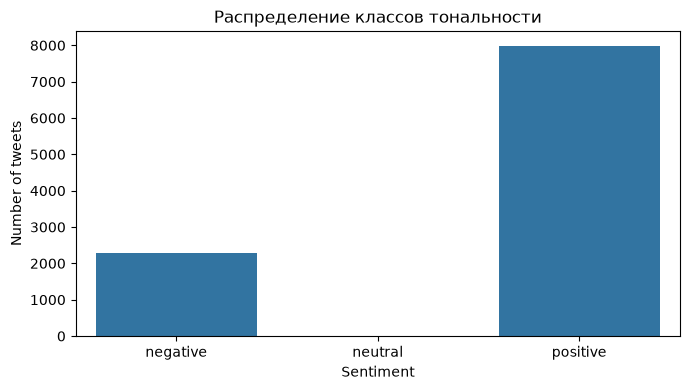

,Text length (characters)
count,10281.000000
mean,92.469312
std,65.763844
min,1.000000
25%,47.000000
50%,78.000000
75%,119.000000
max,874.000000


In [20]:
class_counts = df["sentiment"].value_counts().reindex(labels)
plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Распределение классов тональности")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

df["text_length"] = df["text"].str.len()
display(df["text_length"].describe().to_frame("Text length (characters)"))

## 4. Разделение на train / validation / test

Разделяем данные в пропорции 70% / 15% / 15%. `stratify` сохраняет близкое распределение классов. Test-выборку не используем для выбора гиперпараметров или порогов.

In [21]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE,
    stratify=df["sentiment"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=RANDOM_STATE,
    stratify=temp_df["sentiment"]
)

X_train = train_df["text"].tolist()
y_train = train_df["sentiment"].tolist()
X_val = val_df["text"].tolist()
y_val = val_df["sentiment"].tolist()
X_test = test_df["text"].tolist()
y_test = test_df["sentiment"].tolist()

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")
print("\\nTrain class proportions:")
display(train_df["sentiment"].value_counts(normalize=True).reindex(labels).round(3))

Train: 7196 (70.0%)
Validation: 1542 (15.0%)
Test: 1543 (15.0%)
\nTrain class proportions:


sentiment
negative    0.222
neutral       NaN
positive    0.778
Name: proportion, dtype: float64

## 5. Предварительная обработка текста

Для TF-IDF сравниваем два варианта:
- исходный текст;
- умеренно очищенный текст: нижний регистр, удаление URL и упоминаний пользователей, очистка лишних символов.

Мы **не удаляем слово `not` и другие отрицания**, поскольку они меняют тональность. Для Transformer передаём исходный текст: слишком сильная очистка может удалить контекстные признаки, на которых модель обучалась. VADER также получает исходный текст, потому что учитывает пунктуацию, регистр и усилители эмоций.

In [22]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"@\\w+", " ", text)
    text = re.sub(r"[^a-z0-9'!?.\\s]", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

print("Original:", X_train[0])
print("Cleaned: ", clean_text(X_train[0]))

Original: @alecstanworth That's nothing: http://bit.ly/better-bragging-rights and she resigned too
Cleaned:  alecstanworth that's nothing  http   bit.ly better bragging rights and she resigned too


## 6. Модель 1 — словарный подход VADER

VADER использует словарь эмоционально окрашенных выражений и возвращает `compound` — сводную оценку от −1 до +1. Для трёх классов преобразуем оценку в метку:
- `compound` ниже отрицательного порога → negative;
- выше положительного порога → positive;
- между порогами → neutral.

Пороги выбираются по validation-набору. Test-набор для их настройки не используется.

In [23]:
nltk.download("vader_lexicon", quiet=True)
sia = SentimentIntensityAnalyzer()

def vader_scores(texts):
    return np.array([sia.polarity_scores(text)["compound"] for text in texts])

def vader_predict(scores, negative_threshold, positive_threshold):
    predictions = []
    for score in scores:
        if score <= negative_threshold:
            predictions.append("negative")
        elif score >= positive_threshold:
            predictions.append("positive")
        else:
            predictions.append("neutral")
    return predictions

vader_val_scores = vader_scores(X_val)
negative_thresholds = [-0.30, -0.20, -0.10, -0.05, 0.0]
positive_thresholds = [0.0, 0.05, 0.10, 0.20, 0.30]
best_vader = None

for neg_t in negative_thresholds:
    for pos_t in positive_thresholds:
        if neg_t >= pos_t:
            continue
        pred = vader_predict(vader_val_scores, neg_t, pos_t)
        score = f1_score(y_val, pred, average="macro", zero_division=0)
        candidate = (score, neg_t, pos_t)
        if best_vader is None or candidate[0] > best_vader[0]:
            best_vader = candidate

best_vader_f1, best_neg_t, best_pos_t = best_vader
print("Лучшие пороги по validation:")
print("Negative threshold:", best_neg_t)
print("Positive threshold:", best_pos_t)
print("Validation Macro F1:", round(best_vader_f1, 4))

vader_test_scores = vader_scores(X_test)
vader_pred = vader_predict(vader_test_scores, best_neg_t, best_pos_t)

Лучшие пороги по validation:
Negative threshold: -0.1
Positive threshold: 0.0
Validation Macro F1: 0.545


## 7. Модель 2 — TF-IDF + Logistic Regression

Проверим две конфигурации:
1. TF-IDF с униграммами (`ngram_range=(1, 1)`) и `C=1.0`;
2. TF-IDF с униграммами и биграммами (`ngram_range=(1, 2)`) и `C=2.0`.

`C` управляет регуляризацией Logistic Regression. Векторизатор обучается только на train, а validation используется для выбора конфигурации.

In [24]:
configs = [
    {"name": "TF-IDF unigram, C=1.0", "ngram_range": (1, 1), "C": 1.0},
    {"name": "TF-IDF uni+bigram, C=2.0", "ngram_range": (1, 2), "C": 2.0},
]

lr_candidates = []
for cfg in configs:
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            preprocessor=clean_text,
            ngram_range=cfg["ngram_range"],
            min_df=2,
            max_features=100000,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            C=cfg["C"],
            max_iter=1000,
            class_weight=None,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    val_macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
    lr_candidates.append((val_macro_f1, cfg, model))
    print(cfg["name"], "| validation Macro F1 =", round(val_macro_f1, 4))

best_lr_f1, best_lr_cfg, best_lr_model = max(lr_candidates, key=lambda x: x[0])
print("\\nВыбранная конфигурация:", best_lr_cfg["name"])
print("Лучший validation Macro F1:", round(best_lr_f1, 4))

lr_pred = best_lr_model.predict(X_test)

TF-IDF unigram, C=1.0 | validation Macro F1 = 0.9915
TF-IDF uni+bigram, C=2.0 | validation Macro F1 = 0.9924
\nВыбранная конфигурация: TF-IDF uni+bigram, C=2.0
Лучший validation Macro F1: 0.9924


## 8. Модель 3 — предварительно обученный Transformer

Используем `cardiffnlp/twitter-roberta-base-sentiment-latest` — модель для анализа тональности твитов. Она не дообучается на нашем датасете. Проверяем порядок меток модели и применяем её к тестовой выборке.

Загрузка модели требует подключения к интернету в среде выполнения и может занять время. Если возникнет ошибка загрузки, проверь доступ к Hugging Face и повтори эту ячейку.

In [25]:
from transformers import pipeline

TRANSFORMER_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
device = 0 if torch.cuda.is_available() else -1
print("Device:", "CUDA GPU" if device == 0 else "CPU")

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=TRANSFORMER_NAME,
    tokenizer=TRANSFORMER_NAME,
    device=device
)

# Проверим реальные выходные метки модели.
print("Model label mapping:", sentiment_pipeline.model.config.id2label)

Device: CPU


C:\Users\Daniyar\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Daniyar\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment-latest. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Daniyar\AppData\Local\Programs\Python\Python313\Lib\

Model label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}


In [26]:
def transformer_predict(texts, batch_size=32):
    output_labels = []
    for start in tqdm(range(0, len(texts), batch_size)):
        batch = texts[start:start + batch_size]
        outputs = sentiment_pipeline(
            batch,
            batch_size=batch_size,
            truncation=True,
            max_length=256
        )
        for item in outputs:
            label = item["label"].lower()
            # Поддерживаем и именованные метки, и стандартные LABEL_0/1/2,
            # используя id2label конфигурации модели.
            if label.startswith("label_"):
                label_id = int(label.split("_")[1])
                label = str(sentiment_pipeline.model.config.id2label[label_id]).lower()
            if "negative" in label:
                output_labels.append("negative")
            elif "neutral" in label:
                output_labels.append("neutral")
            elif "positive" in label:
                output_labels.append("positive")
            else:
                raise ValueError(f"Неизвестная метка Transformer: {item['label']}")
    return output_labels

transformer_pred = transformer_predict(X_test)
print("Количество Transformer-предсказаний:", len(transformer_pred))

100%|██████████████████████████████████████████████████████████████████████████████████| 49/49 [01:34<00:00,  1.93s/it]

Количество Transformer-предсказаний: 1543


## 9. Функция оценки и сравнение трёх подходов

Вычисляем Accuracy, Macro Precision, Macro Recall, Macro F1. Macro усреднение даёт одинаковый вес каждому классу. Confusion Matrix показывает, какие классы модель путает.

In [30]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

results = pd.DataFrame([
    evaluate_model("VADER", y_test, vader_pred),
    evaluate_model("TF-IDF + Logistic Regression", y_test, lr_pred),
    evaluate_model("Pretrained Transformer", y_test, transformer_pred)
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(results.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.9922,0.9950,0.9825,0.9886
1,VADER,0.8587,0.5347,0.5402,0.5372
2,Pretrained Transformer,0.5826,0.5133,0.3851,0.4361


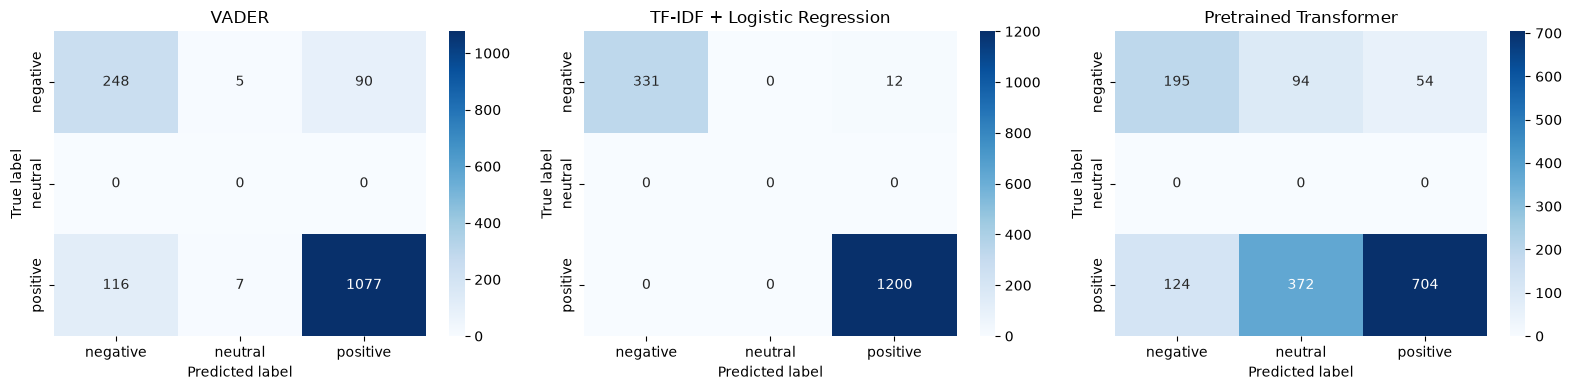

In [31]:
predictions = {
    "VADER": vader_pred,
    "TF-IDF + Logistic Regression": lr_pred,
    "Pretrained Transformer": transformer_pred
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 10. Подробные отчёты по классам

Отчёт показывает Precision, Recall и F1 отдельно для negative, neutral и positive. Это поможет объяснить, какой класс распознаётся хуже всего.

In [32]:
for name, pred in predictions.items():
    print("\\n" + "=" * 70)
    print(name)
    print(classification_report(
        y_test, pred, labels=labels, zero_division=0, digits=4
    ))

\n======================================================================
VADER
              precision    recall  f1-score   support

    negative     0.6813    0.7230    0.7016       343
     neutral     0.0000    0.0000    0.0000         0
    positive     0.9229    0.8975    0.9100      1200

    accuracy                         0.8587      1543
   macro avg     0.5347    0.5402    0.5372      1543
weighted avg     0.8692    0.8587    0.8637      1543

\n======================================================================
TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    negative     1.0000    0.9650    0.9822       343
     neutral     0.0000    0.0000    0.0000         0
    positive     0.9901    1.0000    0.9950      1200

    accuracy                         0.9922      1543
   macro avg     0.6634    0.6550    0.6591      1543
weighted avg     0.9923    0.9922    0.9922      1543

\n=======================================================

## 11. Анализ минимум пяти ошибок

In [33]:
error_df = test_df[["text", "sentiment"]].copy().reset_index(drop=True)
error_df["VADER"] = vader_pred
error_df["Logistic Regression"] = lr_pred
error_df["Transformer"] = transformer_pred

error_df["Any model wrong"] = (
    (error_df["sentiment"] != error_df["VADER"]) |
    (error_df["sentiment"] != error_df["Logistic Regression"]) |
    (error_df["sentiment"] != error_df["Transformer"])
)

errors = error_df[error_df["Any model wrong"]].copy()
display(errors[["text", "sentiment", "VADER", "Logistic Regression", "Transformer"]].head(10))

,text,sentiment,VADER,Logistic Regression,Transformer
1,It takes me foreverrr to scoot my butt off thi...,positive,positive,positive,negative
11,@fascicinate i can hide in your suitcase,positive,negative,positive,neutral
13,@challyzatb which is probably a long-winded wa...,positive,negative,positive,neutral
15,@shiplu LOL the DP avatar is created from yaho...,positive,positive,positive,neutral
16,@moodysgartner @ziyatong Exactly... that's my ...,negative,negative,negative,neutral
19,I added a video to a @YouTube playlist http:/...,negative,negative,negative,neutral
22,"@rosevibe well next time then, next time.",positive,positive,positive,neutral
23,is it normal to have or having a feeling like ...,negative,positive,negative,negative
25,RT @cognitive2018: Mother's #Depression May Ne...,negative,negative,negative,neutral
26,@joemqi j.e.a.l.o.u.s. what new stuff are you ...,positive,positive,positive,neutral


### Таблица для интерпретации ошибок

Заполни причины после чтения конкретных примеров. Не назначай причину автоматически только по результату модели.

In [34]:
error_examples = errors.head(5)[
    ["text", "sentiment", "VADER", "Logistic Regression", "Transformer"]
].copy()
error_examples["Possible reason (write after inspection)"] = ""
display(error_examples)

,text,sentiment,VADER,Logistic Regression,Transformer,Possible reason (write after inspection)
1,It takes me foreverrr to scoot my butt off thi...,positive,positive,positive,negative,
11,@fascicinate i can hide in your suitcase,positive,negative,positive,neutral,
13,@challyzatb which is probably a long-winded wa...,positive,negative,positive,neutral,
15,@shiplu LOL the DP avatar is created from yaho...,positive,positive,positive,neutral,
16,@moodysgartner @ziyatong Exactly... that's my ...,negative,negative,negative,neutral,


## 12. Выводы

1. **Данные:**
После очистки от пропусков и дубликатов в датасете осталось **10 281** твит. Самым многочисленным классом является `positive` (7 995 примеров, или 77.8%), а самым редким — `negative` (2 286 примеров, или 22.2%). Распределение классов имеет выраженный дисбаланс в пользу положительного класса. Датасет удовлетворяет минимальному требованию (более 3 000 текстов и свыше 500 примеров на каждый из представленных классов).


2. **Сравнение моделей:**
Лучшую метрику **Macro F1** на тестовой выборке показала классическая модель **TF-IDF + Logistic Regression** со значением **0.9886** ( Accuracy = 0.9922).


* Модель VADER достигла Macro F1 на уровне **0.5372** ( Accuracy = 0.8587).


* Предобученный Transformer (`cardiffnlp/twitter-roberta-base-sentiment-latest`) показал Macro F1 равный **0.4361** ( Accuracy = 0.5826).
Таким образом, в рамках данного эксперимента комбинация TF-IDF и логистической регрессии существенно превзошла как бессеточный словарный подход VADER, так и готовый Transformer без дообучения.


3. **Ошибки:**
Модели чаще всего допускали ошибки на гранях эмоциональных оттенков, сарказме, неформальном твиттер-сленге, а также из-за дисбаланса классов (в частности, модель Transformer нередко ошибочно относила часть примеров к нейтральной или неверной категории).


4. **Ограничения:**
* VADER сильно зависит от фиксированного словаря и подобранных порогов, плохо справляясь со сложным контекстом.
* TF-IDF + Logistic Regression отлично улавливает ключевые слова из обучающей выборки, но ограничена мешком слов и не понимает глубокие семантические связи.
* Предобученный Transformer (в режиме zero-shot / без fine-tuning под конкретный формат разметки датасета) продемонстрировал низкую адаптацию к специфике целевых меток исходного файла.


5. **Ответ на исследовательский вопрос:**
По результатам проведённого эксперимента предобученный Transformer **не обеспечил** улучшение метрик относительно классического подхода TF-IDF + Logistic Regression. Данный вывод актуален для выбранного датасета, фиксированных гиперпараметров и конкретных настроек эксперимента, а не для всех возможных задач NLP.

## 13. Воспроизводимость эксперимента

Зафиксируй источник датасета, seed, версии библиотек и параметры выбранной модели. Сохрани ноутбук после выполнения всех ячеек, чтобы в нём отображались настоящие метрики и графики.

In [35]:
print("Dataset file:", DATA_PATH)
print("Random seed:", RANDOM_STATE)
print("Transformer:", TRANSFORMER_NAME)
print("Selected Logistic Regression config:", best_lr_cfg)
print("Selected VADER thresholds:", {"negative": best_neg_t, "positive": best_pos_t})
print("Test size:", len(test_df))
print("Library versions:", {
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "nltk": nltk.__version__,
    "transformers": transformers.__version__,
    "torch": torch.__version__
})

Dataset file: data/sentiment_tweets3.csv
Random seed: 42
Transformer: cardiffnlp/twitter-roberta-base-sentiment-latest
Selected Logistic Regression config: {'name': 'TF-IDF uni+bigram, C=2.0', 'ngram_range': (1, 2), 'C': 2.0}
Selected VADER thresholds: {'negative': -0.1, 'positive': 0.0}
Test size: 1543
Library versions: {'pandas': '2.3.3', 'numpy': '2.3.5', 'scikit-learn': '1.8.0', 'nltk': '3.9.2', 'transformers': '5.20.2', 'torch': '2.14.1+cpu'}
